# Playground - Apartment Prices Prediction
by $\mathbb{JX}$

## Setup

In [33]:
import math
import re
import warnings
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from scipy.stats import gaussian_kde, t as t_dist

In [34]:
# plotting helpers for EDA
def plot_hist(df, col, log=False, bins=50):
    """Histogram of one numeric column; log=True plots log(1 + col)."""
    sl_plot = df[col].dropna()
    if log:
        sl_plot = np.log1p(sl_plot)
    label = f'log(1 + {col})' if log else col

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(sl_plot, bins=bins)
    ax.set_title(label)
    ax.set_xlabel(label)
    ax.set_ylabel('count')
    plt.show()

def plot_counts(df, l_cols, levels=None):
    """Bar chart of counts per level, one panel per column (shared y-axis), for discrete columns.
    levels: e.g. range(1, 11) to keep levels with zero houses on the x-axis."""
    fig, axes = plt.subplots(1, len(l_cols), figsize=(6 * len(l_cols), 4), sharey=True, squeeze=False)
    for ax, col in zip(axes.flat, l_cols):
        sl_counts = df[col].value_counts().sort_index()
        if levels is not None:
            sl_counts = sl_counts.reindex(levels, fill_value=0)
        ax.bar(sl_counts.index.astype(str), sl_counts.values)
        ax.set_title(col)
    axes[0, 0].set_ylabel('count')
    plt.tight_layout()
    plt.show()

def plot_boxes(df, l_cols, ncols=4):
    """One boxplot per column (own y-axis each, since scales differ)."""
    nrows = math.ceil(len(l_cols) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.5 * nrows), squeeze=False)
    for ax, col in zip(axes.flat, l_cols):
        ax.boxplot(df[col].dropna())
        ax.set_title(col)
        ax.set_xticks([])
    for ax in axes.flat[len(l_cols):]:  # hide unused panels
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()

def plot_scatter(df, x, y, alpha=0.4):
    """Scatter of y against x, with their correlation in the title."""
    r = df[x].corr(df[y])

    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(df[x], df[y], alpha=alpha)
    ax.set_title(f'{y} vs {x}  (r = {r:.2f})')
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    plt.show()

def plot_densities(df, col, by, log=False, min_n=5, width=0.8):
    """Half-violin density (KDE) of col for each level of `by`, levels sorted by median; log=True plots log(1 + col).
    Groups with fewer than min_n rows are drawn as dots, since a KDE of a handful of points is meaningless."""
    sl_plot = np.log1p(df[col]) if log else df[col]
    label = f'log(1 + {col})' if log else col
    df_plot = pd.DataFrame({'y': sl_plot, 'g': df[by]}).dropna()
    l_levels = df_plot.groupby('g')['y'].median().sort_values().index
    n_by_level = df_plot['g'].value_counts()

    fig, ax = plt.subplots(figsize=(max(8, 0.6 * len(l_levels)), 5))
    for i, level in enumerate(l_levels):
        sl_g = df_plot.loc[df_plot['g'] == level, 'y']
        color = f'C{i % 10}'
        if len(sl_g) >= min_n:
            y_grid = np.linspace(sl_g.min(), sl_g.max(), 200)
            dens = gaussian_kde(sl_g)(y_grid)
            x = i + width * dens / dens.max()  # every group's peak gets the same width
            ax.plot(x, y_grid, color=color)
            ax.fill_betweenx(y_grid, i, x, color=color, alpha=0.2)
        else:
            ax.scatter(np.full(len(sl_g), i), sl_g, color=color, s=12)
        ax.plot([i, i + width], [sl_g.median()] * 2, color=color, linewidth=1, linestyle=':')  # group median
    ax.axhline(df_plot['y'].median(), color='red', linestyle='--', linewidth=1, label='overall median')
    ax.set_xticks(range(len(l_levels)), [f'{level} (n={n_by_level[level]})' for level in l_levels], rotation=90)
    ax.set_title(f'density of {label} by {by}, sorted by median')
    ax.set_xlabel(by)
    ax.set_ylabel(label)
    ax.legend()
    plt.tight_layout()
    plt.show()

def plot_box_strip(df, col, by, log=False, jitter=0.15, seed=0):
    """Boxplot of col for each level of `by` (sorted by median), with every row overlaid as a jittered dot; log=True plots log(1 + col)."""
    sl_plot = np.log1p(df[col]) if log else df[col]
    label = f'log(1 + {col})' if log else col
    df_plot = pd.DataFrame({'y': sl_plot, 'g': df[by]}).dropna()
    l_levels = df_plot.groupby('g')['y'].median().sort_values().index
    l_groups = [df_plot.loc[df_plot['g'] == level, 'y'] for level in l_levels]
    rng = np.random.default_rng(seed)  # fixed seed so the jitter doesn't move on every re-run

    fig, ax = plt.subplots(figsize=(max(8, 0.6 * len(l_levels)), 5))
    ax.boxplot(l_groups, positions=range(len(l_levels)), widths=0.6, showfliers=False)  # outliers already shown as dots
    for i, sl_g in enumerate(l_groups):
        ax.scatter(i + rng.uniform(-jitter, jitter, len(sl_g)), sl_g, s=6, alpha=0.4, color=f'C{i % 10}')
    ax.axhline(df_plot['y'].median(), color='red', linestyle='--', linewidth=1, label='overall median')
    ax.set_xticks(range(len(l_levels)), [f'{level} (n={len(sl_g)})' for level, sl_g in zip(l_levels, l_groups)], rotation=90)
    ax.set_title(f'{label} by {by}, sorted by median')
    ax.set_xlabel(by)
    ax.set_ylabel(label)
    ax.legend()
    plt.tight_layout()
    plt.show()

def plot_group_means(df, col, by, log=False, l_controls=None, level=0.95):
    """Mean of col for each level of `by` (sorted) with t-based confidence intervals, plus a joint F-test of
    H0: all group means are equal (regression on the group dummies, HC1-robust). With l_controls, the F-test is
    repeated holding those columns fixed. log=True uses log(col). Returns the table of group stats."""
    sl_y = np.log(df[col]) if log else df[col]
    label = f'log({col})' if log else col
    df_plot = pd.DataFrame({'y': sl_y, 'g': df[by]}).dropna()
    df_stats = df_plot.groupby('g')['y'].agg(['size', 'mean', 'std']).rename(columns={'size': 'n'})
    df_stats['se'] = df_stats['std'] / np.sqrt(df_stats['n'])
    df_stats['ci_half'] = t_dist.ppf((1 + level) / 2, df_stats['n'] - 1) * df_stats['se']  # t, not 1.96: small groups get wider CIs
    df_stats = df_stats.sort_values('mean')

    ## joint F-test: y on the group dummies (+ controls); H0 = every dummy coefficient is 0
    for l_ctrl in [[]] + ([l_controls] if l_controls else []):
        X = pd.get_dummies(df[by], prefix=by, drop_first=True, dtype=float)
        l_dummies = list(X.columns)
        X = sm.add_constant(pd.concat([X, df[l_ctrl]], axis=1))
        res = sm.OLS(sl_y, X, missing='drop').fit(cov_type='HC1')
        ft = res.f_test(np.eye(X.shape[1])[[X.columns.get_loc(c) for c in l_dummies]])
        ctrl_text = f'controlling for {l_ctrl}' if l_ctrl else 'no controls'
        print(f'{by} ({ctrl_text}): F = {np.squeeze(ft.fvalue):.1f} on {len(l_dummies)} dummies, p = {float(ft.pvalue):.2g}, R² = {res.rsquared:.3f}')

    fig, ax = plt.subplots(figsize=(max(8, 0.6 * len(df_stats)), 5))
    ax.errorbar(range(len(df_stats)), df_stats['mean'], yerr=df_stats['ci_half'], fmt='o', capsize=3)
    ax.axhline(df_plot['y'].mean(), color='red', linestyle='--', linewidth=1, label='overall mean')
    ax.set_xticks(range(len(df_stats)), [f'{g} (n={n})' for g, n in df_stats['n'].items()], rotation=90)
    ax.set_title(f'mean {label} by {by}, with {level:.0%} CIs, sorted')
    ax.set_xlabel(by)
    ax.set_ylabel(label)
    ax.legend()
    plt.tight_layout()
    plt.show()
    return df_stats.round(3)

In [35]:
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
# only the literal string "NA" becomes NaN: pandas' default would also turn MasVnrType's "None" (= no veneer) into NaN
read_kwargs = dict(keep_default_na=False, na_values=['NA'])
df_data = pd.read_csv(ROOT / "data" / "train.csv", **read_kwargs)
df_test = pd.read_csv(ROOT / "data" / "test.csv", **read_kwargs)

## Understanding the dataset + cleaning

In [36]:
df_data.duplicated().sum()  # 0

np.int64(0)

In [37]:
# NA summary across train AND test (features only), split by what NA means for each column
## columns where data_description.txt lists NA as a code, i.e. NA = feature absent (e.g. "NA  No Garage")
l_na_coded = []
col = None
for line in open(ROOT / "data" / "data_description.txt"):
    m = re.match(r'^(\w+):', line)  # column header line, e.g. "Alley: Type of alley access to property"
    if m:
        col = m.group(1)
    elif col and re.match(r'^\s+NA\s', line):  # indented value line for the code NA
        l_na_coded.append(col)

l_features = df_test.columns  # everything except SalePrice
na_summary = pd.DataFrame({
    "na_train": df_data[l_features].isna().sum(),
    "na_test": df_test.isna().sum(),
    "pct_na_train": round(df_data[l_features].isna().mean()*100, 2),
    "pct_na_test": round(df_test.isna().mean()*100, 2),
})
na_summary['na_means'] = np.where(na_summary.index.isin(l_na_coded), 'absent', 'MISSING')
na_summary = na_summary[(na_summary['na_train'] + na_summary['na_test']) > 0]
na_summary.sort_values(['na_means', 'na_train', 'na_test'], ascending=[True, False, False])

,na_train,na_test,pct_na_train,pct_na_test,na_means
LotFrontage,259,227,17.74,15.56,MISSING
GarageYrBlt,81,78,5.55,5.35,MISSING
MasVnrType,8,16,0.55,1.10,MISSING
MasVnrArea,8,15,0.55,1.03,MISSING
Electrical,1,0,0.07,0.00,MISSING
MSZoning,0,4,0.00,0.27,MISSING
Utilities,0,2,0.00,0.14,MISSING
BsmtFullBath,0,2,0.00,0.14,MISSING
BsmtHalfBath,0,2,0.00,0.14,MISSING
Functional,0,2,0.00,0.14,MISSING


### Cleaning NAs

Only the columns with NAs in train **or** test (see the NA summary above), one group at a time. Each decision is one of two kinds:
* **Kind A - fixed rules** (e.g. NA → `"None"` where the feature is absent, typo fixes, dropping a column): learn nothing from the data, so they go in a `clean_*(df)` function applied to train and test alike.
* **Kind B - learned values** (median / mode for genuinely missing values): recorded in `d_impute` (column → `SimpleImputer` strategy) and fitted inside the pipeline, so each CV fold learns them from its own training rows.

In [38]:
d_impute = {}  # column -> SimpleImputer strategy for genuinely missing values; filled in group by group below

#### 1. Garage

* Train: `GarageType` is NA exactly where `GarageArea` = 0 (81 rows) → no garage. Test matches, except 2 houses with a detached garage but missing details (Ids 2127, 2577).
* Test Id 2593: `GarageYrBlt` = 2207 (built 2006, remodelled 2007) → typo for 2007.

| # | Decision | Kind |
|---|---|---|
| 1 | `GarageType`/`Finish`/`Qual`/`Cond` NA where `GarageArea` = 0 → `"None"` | A |
| 2 | Drop `GarageYrBlt`: no sensible value for "no garage", and it equals `YearBuilt` in 79% of houses with a garage | A |
| 3 | Id 2593: `GarageYrBlt` 2207 → 2007 (moot while 2 drops the column) | A |
| 4 | Id 2127: missing `Finish`/`Qual`/`Cond` → mode | B |
| 5 | Id 2577: treat as having a garage; `Finish`/`Qual`/`Cond` → mode, `Cars`/`Area` → median | B |

In [39]:
# garage: kind-A rules (fixed, safe on train and test alike) + kind-B decisions (learned in the pipeline)
l_garage_cat = ['GarageType', 'GarageFinish', 'GarageQual', 'GarageCond']
l_garage_num = ['GarageCars', 'GarageArea']

def clean_garage(df):
    df = df.copy()
    no_garage = df['GarageArea'] == 0  # NaN area (test Id 2577) is NOT counted as "no garage"
    df.loc[no_garage, l_garage_cat] = df.loc[no_garage, l_garage_cat].fillna('None')  # 1. NA = no garage
    df['GarageYrBlt'] = df['GarageYrBlt'].replace(2207, 2007)  # 3. typo (test Id 2593); moot while 2. drops the column
    return df.drop(columns=['GarageYrBlt'])  # 2. mostly repeats YearBuilt (equal in 79% of houses with a garage)

# 4, 5(a). genuinely missing (test Ids 2127, 2577): imputed in the pipeline from the training data
d_impute.update({c: 'most_frequent' for c in ['GarageFinish', 'GarageQual', 'GarageCond']})
d_impute.update({c: 'median' for c in l_garage_num})

## check: rows still with NaNs after the kind-A rules = the genuinely missing ones
for name, df in [('train', df_data), ('test', df_test)]:
    df_c = clean_garage(df)
    df_left = df_c.loc[df_c[l_garage_cat + l_garage_num].isna().any(axis=1), ['Id'] + l_garage_cat + l_garage_num]
    print(f'{name}: {len(df_left)} rows left for the imputer')
    display(df_left)

train: 0 rows left for the imputer


,Id,GarageType,GarageFinish,GarageQual,GarageCond,GarageCars,GarageArea


test: 2 rows left for the imputer


,Id,GarageType,GarageFinish,GarageQual,GarageCond,GarageCars,GarageArea
666,2127,Detchd,NaN,NaN,NaN,1.0,360.0
1116,2577,Detchd,NaN,NaN,NaN,NaN,NaN


#### 2. Basement

* Train: all 37 houses with `TotalBsmtSF` = 0 have all 5 basement categoricals NA → no basement. Test: same for its 41, plus Id 2121, where *every* basement field is NA (the categoricals agree it has none). Test Id 2189 has no basement but NA bath counts.
* Genuinely missing (house has a basement): train 949 (`Exposure`), 333 (`FinType2`); test 1488, 2349 (`Exposure`), 2218, 2219 (`Qual`), 2041, 2186, 2525 (`Cond`).

| # | Decision | Kind |
|---|---|---|
| 1 | No basement (`TotalBsmtSF` = 0, or every basement field NA): 5 categoricals → `"None"`, SF and bath counts → 0 | A |
| 2 | Remaining categorical NAs → mode | B |
| 3 | Id 333's `BsmtFinType2` → plain mode (`Unf`) | B |

On 3: strictly, `Unf` contradicts Id 333's `BsmtFinSF2` = 479 (a second *finished* area). The more correct fill would be the mode among houses with `BsmtFinSF2` > 0, but that's a conditional rule `SimpleImputer` can't do. It's the only such conflict (one training row, none in test), so the plain mode is kept for simplicity; the effect on the model should be negligible.

In [40]:
# basement: kind-A rules (fixed, safe on train and test alike) + kind-B decisions (learned in the pipeline)
l_bsmt_cat = ['BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2']
l_bsmt_num = ['BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'BsmtFullBath', 'BsmtHalfBath']

def clean_basement(df):
    df = df.copy()
    no_bsmt = (df['TotalBsmtSF'] == 0) | df[l_bsmt_cat + l_bsmt_num].isna().all(axis=1)  # 2nd part: test Id 2121, every basement field NA
    df.loc[no_bsmt, l_bsmt_cat] = df.loc[no_bsmt, l_bsmt_cat].fillna('None')  # 1. NA = no basement
    df.loc[no_bsmt, l_bsmt_num] = df.loc[no_bsmt, l_bsmt_num].fillna(0)  # 1. no basement = 0 sq ft, 0 baths
    return df

# 2, 3(a). genuinely missing categoricals (houses that do have a basement): mode, imputed in the pipeline
d_impute.update({c: 'most_frequent' for c in l_bsmt_cat})

## check: rows still with NaNs after the kind-A rules = the genuinely missing ones
for name, df in [('train', df_data), ('test', df_test)]:
    df_c = clean_basement(df)
    df_left = df_c.loc[df_c[l_bsmt_cat + l_bsmt_num].isna().any(axis=1), ['Id'] + l_bsmt_cat + ['TotalBsmtSF']]
    print(f'{name}: {len(df_left)} rows left for the imputer')
    display(df_left)

train: 2 rows left for the imputer


,Id,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,TotalBsmtSF
332,333,Gd,TA,No,GLQ,NaN,3206
948,949,Gd,TA,NaN,Unf,Unf,936


test: 7 rows left for the imputer


,Id,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinType2,TotalBsmtSF
27,1488,Gd,TA,NaN,Unf,Unf,1595.0
580,2041,Gd,NaN,Mn,GLQ,Rec,1426.0
725,2186,TA,NaN,No,BLQ,Unf,1127.0
757,2218,NaN,Fa,No,Unf,Unf,173.0
758,2219,NaN,TA,No,Unf,Unf,356.0
888,2349,Gd,TA,NaN,Unf,Unf,725.0
1064,2525,TA,NaN,Av,ALQ,Unf,995.0


#### 3. Masonry veneer

* Both columns NA: 8 train, 15 test. Test Id 2611: type NA but area 198.
* Contradictions: `"None"` with area 1 (train 774, 1231; test 2453 - a placeholder), `"None"` with real area (train 625, 1301, 1335; test 1670), type set with area 0 (train 689, 1242; test 2320).

One principle: **trust the area**.

| # | Decision | Kind |
|---|---|---|
| 1 | Both NA → type mode, area median (on train: `"None"`, 0 = no veneer) | B |
| 2 | Area ≤ 1 → type `"None"`, area 0 | A |
| 3 | Area > 1 but type `"None"`/NA → `"BrkFace"` (most common veneer type in train: 445 vs Stone 128) | A |

Unlike basement Id 333, a plain mode for 3 would leave contradictions in *test* rows (1670, 2611), which feed straight into their predictions.

In [41]:
# masonry veneer: kind-A rules ("trust the area") + kind-B decisions (learned in the pipeline)
l_mvnr = ['MasVnrType', 'MasVnrArea']

def clean_masonry(df):
    df = df.copy()
    no_vnr = df['MasVnrArea'] <= 1  # 2. area 0, or a 1-sq-ft placeholder = no veneer (NaN area isn't touched: left for the imputer)
    df.loc[no_vnr, 'MasVnrType'] = 'None'
    df.loc[no_vnr, 'MasVnrArea'] = 0
    has_vnr = (df['MasVnrArea'] > 1) & (df['MasVnrType'].isna() | (df['MasVnrType'] == 'None'))
    df.loc[has_vnr, 'MasVnrType'] = 'BrkFace'  # 3. real veneer but type missing / "None" -> most common veneer type in train
    return df

# 1. both columns NA: imputed in the pipeline (on train: mode "None", median 0 = no veneer)
d_impute.update({'MasVnrType': 'most_frequent', 'MasVnrArea': 'median'})

## check: rows still with NaNs after the kind-A rules = the genuinely missing ones
for name, df in [('train', df_data), ('test', df_test)]:
    df_c = clean_masonry(df)
    n_left = df_c[l_mvnr].isna().any(axis=1).sum()
    n_conflict = (((df_c['MasVnrType'] == 'None') & (df_c['MasVnrArea'] > 0)) | ((df_c['MasVnrType'] != 'None') & (df_c['MasVnrArea'] == 0))).sum()
    print(f'{name}: {n_left} rows left for the imputer, {n_conflict} type/area contradictions left')

train: 8 rows left for the imputer, 0 type/area contradictions left
test: 15 rows left for the imputer, 0 type/area contradictions left


#### 4. Pool, Misc, Fireplace, Alley, Fence

* `FireplaceQu` is NA exactly where `Fireplaces` = 0 (train and test). `Alley` and `Fence` have no companion column, so nothing can contradict them.
* `PoolQC`: only 7 pools in train; test 2421, 2504, 2600 have `PoolArea` > 0 but `PoolQC` NA.
* `MiscFeature`: test 2550 has `MiscVal` = $17,000 but the feature NA; train 874, 1201 and test 2432 have a feature but `MiscVal` = 0.

| # | Decision | Kind |
|---|---|---|
| 1 | `FireplaceQu`, `Alley`, `Fence`: NA → `"None"`, keep. Despite > 80% NA (slides' drop rule), the NAs mean "absent", not unknown, and carry signal (e.g. median log price: no fireplace 11.81 vs Gd 12.24; gravel alley 11.69 vs none 12.01). Lasso can drop them if they don't help | A |
| 2 | Drop `PoolQC`: `PoolArea` already says whether there's a pool and how big; 7 pools can't teach a quality rating; removes the 3 test contradictions | A |
| 3 | Drop `MiscFeature`: `MiscVal` carries the dollar value; removes Id 2550's contradiction and the 3 "feature but $0" rows | A |

In [42]:
# fireplace, alley, fence, pool, misc: kind-A rules only
l_na_absent = ['FireplaceQu', 'Alley', 'Fence']

def clean_extras(df):
    df = df.copy()
    df[l_na_absent] = df[l_na_absent].fillna('None')  # 1. NA = no fireplace / alley access / fence (no contradictions in train or test)
    return df.drop(columns=['PoolQC', 'MiscFeature'])  # 2, 3. PoolArea and MiscVal already carry the information

## check: no NaNs should be left in these columns
for name, df in [('train', df_data), ('test', df_test)]:
    df_c = clean_extras(df)
    print(f"{name}: {df_c[l_na_absent + ['PoolArea', 'MiscVal']].isna().sum().sum()} NaNs left")

train: 0 NaNs left
test: 0 NaNs left


#### 5. LotFrontage

* Genuinely missing (NA isn't a code): 259 train (17.7%), 227 test. Not at random: 52% of cul-de-sac lots are missing vs 13% of inside lots, and missing lots are bigger.
* Options considered: overall median (+ missing indicator), median by `Neighborhood`, regression on √`LotArea`, or drop.

| # | Decision | Kind |
|---|---|---|
| 1 | **Drop `LotFrontage`** | A |

Why: it's hard to interpret consistently. A corner lot can have double or triple the frontage of an otherwise identical house (cul-de-sac lots are the opposite case), so there's too much to normalise against. `LotArea` already carries the lot-size information.

In [43]:
# lot frontage: kind-A rule only
def clean_lotfrontage(df):
    return df.drop(columns=['LotFrontage'])  # 1. too many interpretations (corner / cul-de-sac lots); LotArea covers lot size

#### 6. One-off missing values

`Electrical` (train Id 1380); test only: `MSZoning` (1916, 2217, 2251, 2905), `Utilities` (1916, 1946), `Functional` (2217, 2474), `Exterior1st`/`2nd` (2152), `KitchenQual` (1556), `SaleType` (2490).

| # | Decision | Kind |
|---|---|---|
| 1 | Drop `Utilities`: train has 1,459 `AllPub` and 1 `NoSeWa`, test is all `AllPub`, so it isn't informative | A |
| 2 | `Functional` NA → `"Typ"`, per data_description: "Assume typical unless deductions are warranted" | A |
| 3 | `Electrical`, `Exterior1st`/`2nd`, `KitchenQual`, `SaleType` → mode | B |
| 4 | `MSZoning` → plain mode (`RL`) | B |

On 4: zoning matters for price (train medians: RL \$174k, RM \$120.5k, C \$74.7k), and three of the four houses (1916, 2217, 2251) are in IDOTRR, where **no** training house is RL (28 RM, 9 C). So the plain mode knowingly gives them a zoning class their neighbourhood doesn't have, which will likely push their predictions up. The alternative was the neighbourhood's mode (IDOTRR → `RM`). Plain mode is kept for now for simplicity; it only affects these three test predictions. Revisit if needed.

In [44]:
# one-off missing values: kind-A rules + kind-B decisions (learned in the pipeline)
l_oneoff_mode = ['Electrical', 'Exterior1st', 'Exterior2nd', 'KitchenQual', 'SaleType', 'MSZoning']

def clean_oneoffs(df):
    df = df.copy()
    df['Functional'] = df['Functional'].fillna('Typ')  # 2. data_description: "Assume typical unless deductions are warranted"
    return df.drop(columns=['Utilities'])  # 1. 1 non-AllPub house in 2,919: not informative

# 3, 4. genuinely missing: mode, imputed in the pipeline (MSZoning: plain mode, knowingly - see the note above)
d_impute.update({c: 'most_frequent' for c in l_oneoff_mode})

## check: rows still with NaNs after the kind-A rules = the genuinely missing ones
for name, df in [('train', df_data), ('test', df_test)]:
    df_c = clean_oneoffs(df)
    df_left = df_c.loc[df_c[l_oneoff_mode + ['Functional']].isna().any(axis=1), ['Id', 'Neighborhood'] + l_oneoff_mode]
    print(f'{name}: {len(df_left)} rows left for the imputer')
    display(df_left)

train: 1 rows left for the imputer


,Id,Neighborhood,Electrical,Exterior1st,Exterior2nd,KitchenQual,SaleType,MSZoning
1379,1380,Timber,NaN,VinylSd,VinylSd,Gd,WD,RL


test: 7 rows left for the imputer


,Id,Neighborhood,Electrical,Exterior1st,Exterior2nd,KitchenQual,SaleType,MSZoning
95,1556,ClearCr,SBrkr,Wd Sdng,Wd Sdng,NaN,COD,RL
455,1916,IDOTRR,FuseA,Wd Sdng,Wd Sdng,TA,ConLD,NaN
691,2152,Edwards,SBrkr,NaN,NaN,Fa,WD,RL
756,2217,IDOTRR,FuseA,AsbShng,VinylSd,Fa,WD,NaN
790,2251,IDOTRR,SBrkr,Wd Sdng,Wd Sdng,TA,WD,NaN
1029,2490,Sawyer,SBrkr,Plywood,Plywood,TA,NaN,RL
1444,2905,Mitchel,FuseA,CBlock,VinylSd,TA,WD,NaN


### Types

| # | Decision | Kind |
|---|---|---|
| 1 | `MSSubClass` → text (`"SC20"`, `"SC60"`, …): it's a dwelling-type code, not a quantity. Test has one level not in train (`SC150`, 1 house), which the encoder treats as the baseline | A |
| 2 | The 9 Ex/Gd/TA/Fa/Po columns (`ExterQual`, `ExterCond`, `BsmtQual`, `BsmtCond`, `HeatingQC`, `KitchenQual`, `FireplaceQu`, `GarageQual`, `GarageCond`) → 0–5 (`None` = 0, `Po` = 1, …, `Ex` = 5): keeps the order, 1 column each instead of ~5 dummies | A |
| 3 | `MoSold` + `YrSold` → `sale_date` = 1st of the sale month, in years (e.g. 2008.25 = 1 Apr 2008); drop the two columns | A |

In [45]:
# types: kind-A rules (fixed, safe on train and test alike)
l_qual_cols = ['ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond', 'HeatingQC', 'KitchenQual', 'FireplaceQu', 'GarageQual', 'GarageCond']
d_qual_map = {'None': 0, 'Po': 1, 'Fa': 2, 'TA': 3, 'Gd': 4, 'Ex': 5}

def clean_types(df):
    df = df.copy()
    df['MSSubClass'] = 'SC' + df['MSSubClass'].astype(str)  # 1. a dwelling-type code, not a quantity (prefix so it never looks numeric)
    for c in l_qual_cols:  # 2. ordered quality scale -> 0-5; NaN stays NaN for the imputer (its mode then works on the numbers)
        assert df[c].dropna().isin(list(d_qual_map)).all(), f'unexpected level in {c}'
        df[c] = df[c].map(d_qual_map)
    df['sale_date'] = df['YrSold'] + (df['MoSold'] - 1) / 12  # 3. 1st of the sale month, in years (e.g. 2008.25 = 1 Apr 2008)
    return df.drop(columns=['MoSold', 'YrSold'])

### Outliers

Drop **training** houses outside their neighbourhood's boxplot whiskers (Q1 − 1.5 IQR, Q3 + 1.5 IQR) on price per sq ft, for neighbourhoods with more than 10 houses (as in the box + strip plots). Test rows are never dropped: every test house needs a prediction.

* On `price_psf` this drops 18 houses (15 of them unusually *expensive* per sq ft for their neighbourhood). On `SalePrice` it would drop 65.
* Ids 524 and 1299 (the huge, cheap Edwards houses) are **not** caught on psf: Edwards' psf spread is wide enough that they sit inside the whiskers.
* Caveat: rows dropped before cross-validation are missing from the validation folds too, while `test.csv` keeps its outliers, so CV scores will look a bit better than the test score.

In [46]:
# outliers: drop TRAINING houses outside their neighbourhood's boxplot whiskers (Q1 - 1.5 IQR, Q3 + 1.5 IQR)
ui_outlier_col = 'price_psf'  # 'price_psf' (the target) or 'SalePrice'
ui_outlier_min_n = 10  # only neighbourhoods with more than this many houses: small ones have unreliable quartiles

def flag_outliers(df, col=ui_outlier_col, min_n=ui_outlier_min_n):
    """True for houses outside their neighbourhood's 1.5 x IQR whiskers on col (same rule as the boxplots)."""
    sl = df['SalePrice'] / df['GrLivArea'] if col == 'price_psf' else df[col]
    grp = sl.groupby(df['Neighborhood'])
    q1, q3 = grp.transform(lambda s: s.quantile(0.25)), grp.transform(lambda s: s.quantile(0.75))
    return (grp.transform('size') > min_n) & ((sl < q1 - 1.5 * (q3 - q1)) | (sl > q3 + 1.5 * (q3 - q1)))

sl_outlier = flag_outliers(df_data)
df_train = df_data[~sl_outlier]  # training rows kept; test rows are never dropped
print(f'dropped {sl_outlier.sum()} of {len(df_data)} training houses on {ui_outlier_col}; {len(df_train)} left')
df_data.loc[sl_outlier, ['Id', 'Neighborhood', 'GrLivArea', 'SalePrice', 'SaleCondition']].assign(
    price_psf=lambda x: (x['SalePrice'] / x['GrLivArea']).round(0)).sort_values(['Neighborhood', 'price_psf'])

dropped 18 of 1460 training houses on price_psf; 1442 left


,Id,Neighborhood,GrLivArea,SalePrice,SaleCondition,price_psf
363,364,BrDale,987,118000,Normal,120.0
92,93,Crawfor,964,163500,Normal,170.0
1310,1311,Crawfor,1902,335000,Normal,176.0
1181,1182,Crawfor,1652,392500,Partial,238.0
724,725,Edwards,1698,320000,Normal,188.0
868,869,Gilbert,2320,169000,Normal,73.0
277,278,Gilbert,864,141000,Normal,163.0
1258,1259,Gilbert,1166,190000,Normal,163.0
1127,1128,Gilbert,1530,259000,Family,169.0
1388,1389,Gilbert,1746,377500,Normal,216.0


### Combine and encode

* **Kind A:** `clean(df)` chains the `clean_*` functions (NA groups 1–6 + types). It learns nothing, so it's applied to train and test directly, before the pipeline.
* **Kind B:** `preprocess` = `imputer` (one `SimpleImputer` per strategy and text/numeric group in `d_impute`) → `encoder` (one-hot for every text column). It goes *inside* the model pipeline, so each CV fold learns its own medians / modes / categories from its own training rows (reading 01).
* `df_X_train` (from `df_train`, outliers dropped) / `df_X_test` hold the features only: no `Id`, no `SalePrice`, no columns added to `df_data` later such as `price_psf`.

In [47]:
# combine: all kind-A rules in one function, applied to train and test alike
def clean(df):
    for f in [clean_garage, clean_basement, clean_masonry, clean_extras, clean_lotfrontage, clean_oneoffs, clean_types]:
        df = f(df)
    return df

l_features = [c for c in clean(df_test).columns if c != 'Id']  # features only: no Id, no SalePrice, no columns added to df_data later (e.g. price_psf)
df_X_train = clean(df_train)[l_features]  # df_train: outliers dropped
df_X_test = clean(df_test)[l_features]

## check: after clean(), the only NaNs left should be in d_impute's columns
for name, df in [('train', df_X_train), ('test', df_X_test)]:
    sl_na = df.isna().sum()[lambda s: s > 0]
    l_unplanned = [c for c in sl_na.index if c not in d_impute]
    print(f'{name}: {sl_na.sum()} NaNs in {len(sl_na)} columns; not covered by d_impute: {l_unplanned}')

train: 19 NaNs in 5 columns; not covered by d_impute: []
test: 53 NaNs in 15 columns; not covered by d_impute: []


In [48]:
# kind-B: one SimpleImputer per (strategy, text/numeric) group of d_impute's columns; all other columns pass through unchanged
# (text and numeric columns get separate imputers: a mixed group would come out as text, and the encoder would then one-hot the numbers)
l_text_cols = df_X_train.select_dtypes(exclude='number').columns
d_groups = {}
for c, strategy in d_impute.items():
    d_groups.setdefault(f"{strategy}_{'text' if c in l_text_cols else 'num'}", (strategy, []))[1].append(c)

imputer = ColumnTransformer(
    [(name, SimpleImputer(strategy=strategy), l_cols) for name, (strategy, l_cols) in d_groups.items()],
    remainder='passthrough',
    verbose_feature_names_out=False,  # keep the original column names
).set_output(transform='pandas')

## check: fit on all of train (in CV, the pipeline refits this per fold), transform both -> no NaNs left
df_X_train_imp = imputer.fit_transform(df_X_train)
df_X_test_imp = imputer.transform(df_X_test)
print('NaNs left: train', df_X_train_imp.isna().sum().sum(), '| test', df_X_test_imp.isna().sum().sum())
print('shapes:', df_X_train_imp.shape, df_X_test_imp.shape)
print('columns whose dtype changed:', [c for c in df_X_train.columns if (c in l_text_cols) != (c in df_X_train_imp.select_dtypes(exclude='number').columns)])

## the values learned from train
pd.DataFrame([
    {'column': c, 'strategy': name, 'fill value': v}
    for name, step, l_cols in imputer.transformers_ if name != 'remainder'
    for c, v in zip(l_cols, step.statistics_)
])

NaNs left: train 0 | test 0
shapes: (1442, 73) (1459, 73)
columns whose dtype changed: []


,column,strategy,fill value
0,GarageFinish,most_frequent_text,Unf
1,BsmtExposure,most_frequent_text,No
2,BsmtFinType1,most_frequent_text,Unf
3,BsmtFinType2,most_frequent_text,Unf
4,MasVnrType,most_frequent_text,None
5,Electrical,most_frequent_text,SBrkr
6,Exterior1st,most_frequent_text,VinylSd
7,Exterior2nd,most_frequent_text,VinylSd
8,SaleType,most_frequent_text,WD
9,MSZoning,most_frequent_text,RL


In [49]:
# kind-B: one-hot encode every text column (the encoder learns each column's categories in fit); numeric columns pass through
encoder = ColumnTransformer(
    [('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), make_column_selector(dtype_exclude='number'))],
    remainder='passthrough',
    verbose_feature_names_out=False,  # dummies named like MSZoning_RL; numeric columns keep their names
).set_output(transform='pandas')
# drop='first': one level per column becomes the baseline, avoiding the dummy trap (perfect collinearity with the intercept) in OLS
# handle_unknown='ignore': a level never seen in training becomes all zeros (i.e. treated like the baseline) instead of an error

preprocess = Pipeline([('impute', imputer), ('encode', encoder)])  # goes at the front of the model pipeline

## check: fit on all of train (in CV, the model pipeline refits this per fold), transform both
df_X_train_enc = preprocess.fit_transform(df_X_train)
df_X_test_enc = preprocess.transform(df_X_test)
print('shapes:', df_X_train_enc.shape, df_X_test_enc.shape, '| NaNs left:', df_X_train_enc.isna().sum().sum(), df_X_test_enc.isna().sum().sum())
print('non-numeric columns left:', list(df_X_train_enc.select_dtypes(exclude='number').columns))
df_X_train_enc.head()

shapes: (1442, 232) (1459, 232) | NaNs left: 0 0
non-numeric columns left: []


/Users/jxwhaat/Documents/C - Library/BSE/1 - Courses/Term 1/22DM012 - Computational Machine Learning/Assignments/Assignment 01/22DM012-assn01-apartmentprices.nosync/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [10, 27] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


,GarageFinish_None,GarageFinish_RFn,GarageFinish_Unf,BsmtExposure_Gd,BsmtExposure_Mn,BsmtExposure_No,BsmtExposure_None,BsmtFinType1_BLQ,BsmtFinType1_GLQ,BsmtFinType1_LwQ,...,Fireplaces,FireplaceQu,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,sale_date
0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,...,0,0,0,61,0,0,0,0,0,2008.083333
1,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,1,3,298,0,0,0,0,0,0,2007.333333
2,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,1,3,0,42,0,0,0,0,0,2008.666667
3,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,...,1,4,0,35,272,0,0,0,0,2006.083333
4,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1,3,192,84,0,0,0,0,0,2008.916667


### Adding features

In [50]:
ui_datasetyear = 2016
df_data['age_eff'] = ui_datasetyear - df_data[['YearBuilt', 'YearRemodAdd']].max(axis=1)

# price per sq ft of above-ground living area; built from the target, so NOT a regressor (test.csv has no SalePrice)
df_data['price_psf'] = df_data['SalePrice'] / df_data['GrLivArea']

## EDA

Distribution of log sale price. Sale price without log-transform has a sizeable right-tail. 

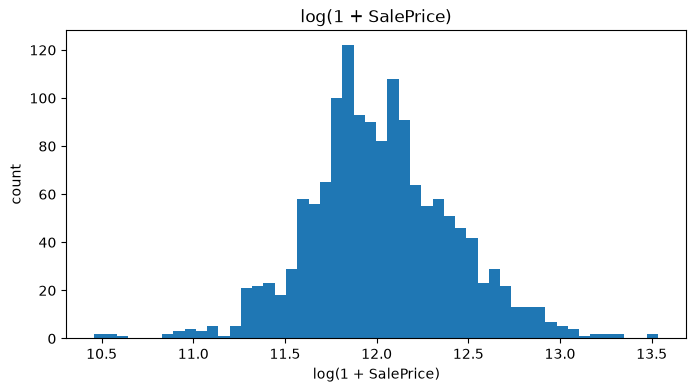

In [51]:
# distribution of a numeric column
plot_hist(df_data, col='SalePrice', log=True, bins=50) # log transform is necessary

For psf: both the raw psf and the log psf are skewed (different directions, the log-transform has more skew)

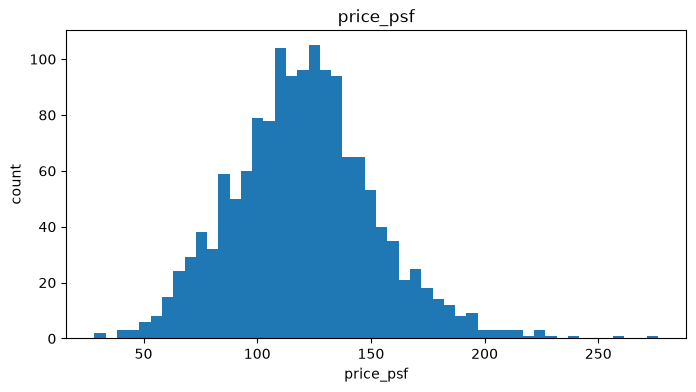

In [52]:
# distribution of psf
plot_hist(df_data, col='price_psf', log=False, bins=50) # log transform is necessary

Distribution of price per sq ft by neighbourhood

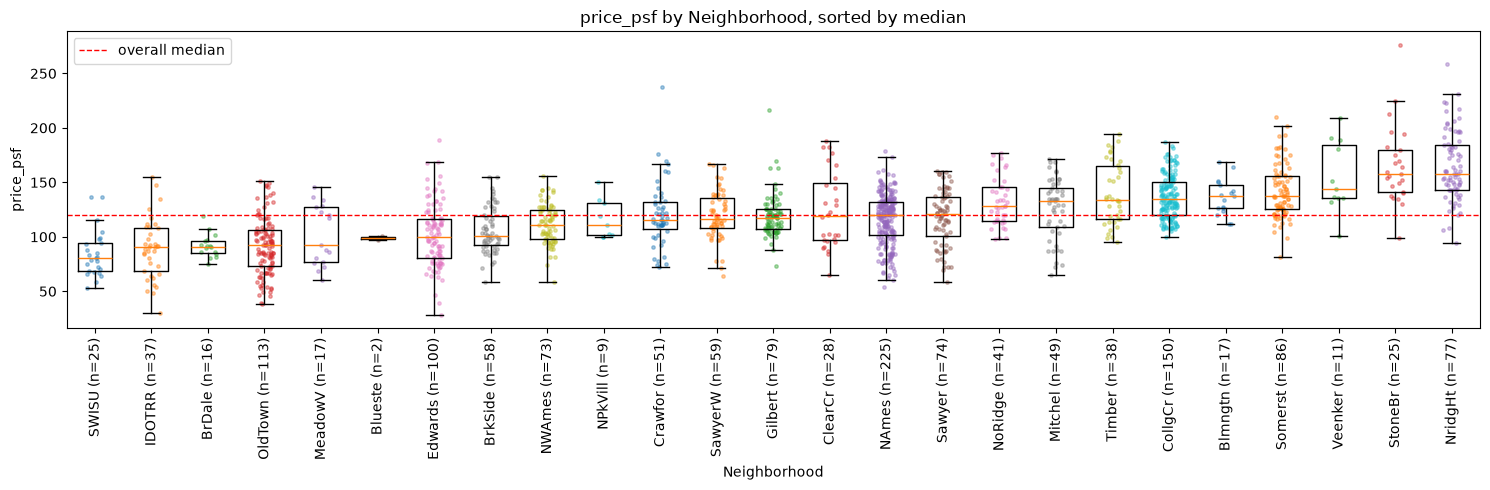

In [53]:
# price per sq ft by neighbourhood: boxplots with every house overlaid
plot_box_strip(df_data, col='price_psf', by='Neighborhood')

Are price-per-sq-ft differences across neighbourhoods meaningful? group means with 95% CIs + joint F-test.

TLDR: yes

Neighborhood (no controls): F = 44.3 on 24 dummies, p = 9e-154, R² = 0.388
Neighborhood (controlling for ['OverallQual', 'OverallCond', 'YearBuilt', 'GrLivArea']): F = 25.4 on 24 dummies, p = 6.5e-93, R² = 0.647


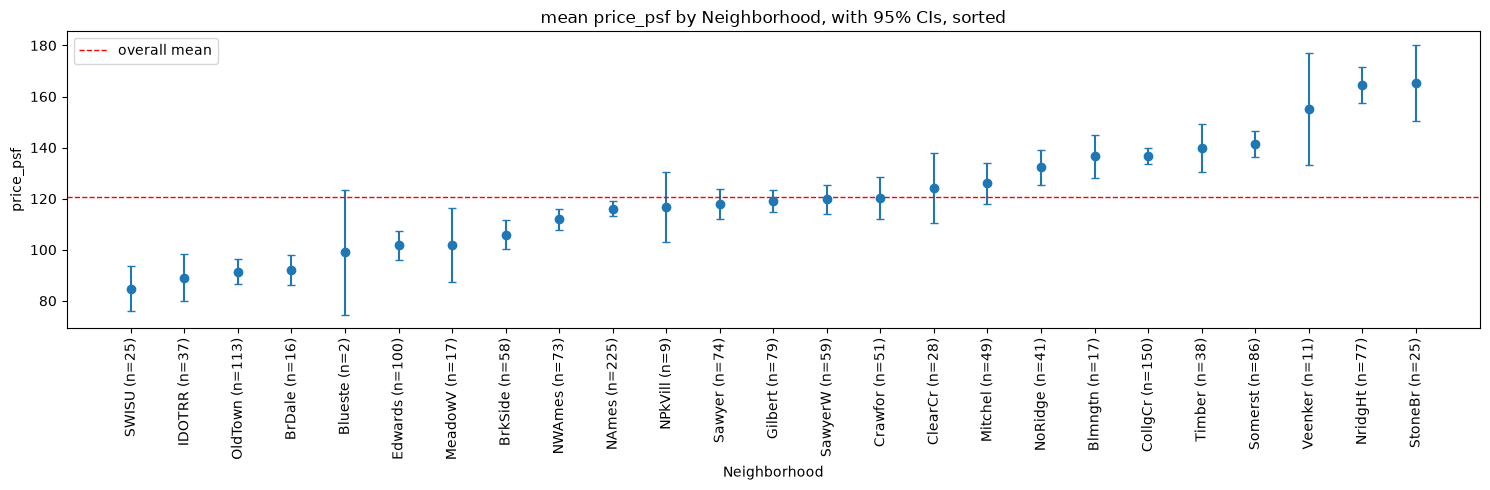

,n,mean,std,se,ci_half
g,,,,,
SWISU,25,84.755,21.559,4.312,8.899
IDOTRR,37,89.136,27.467,4.515,9.158
OldTown,113,91.427,25.983,2.444,4.843
BrDale,16,91.951,10.906,2.726,5.811
Blueste,2,98.969,2.723,1.926,24.468
Edwards,100,101.833,28.563,2.856,5.668
MeadowV,17,101.926,27.987,6.788,14.389
BrkSide,58,105.967,20.957,2.752,5.510
NWAmes,73,111.848,18.391,2.153,4.291


In [54]:
# are price-per-sq-ft differences across neighbourhoods meaningful? group means with 95% CIs + joint F-test
ui_controls = ['OverallQual', 'OverallCond', 'YearBuilt', 'GrLivArea']  # F-test repeated holding these fixed; [] for the raw test only

plot_group_means(df_data, col='price_psf', by='Neighborhood', log=False, l_controls=ui_controls)

Same thing for zoning

MSZoning (no controls): F = 64.2 on 4 dummies, p = 5e-50, R² = 0.111
MSZoning (controlling for ['OverallQual', 'OverallCond', 'YearBuilt', 'GrLivArea']): F = 15.9 on 4 dummies, p = 9.3e-13, R² = 0.572


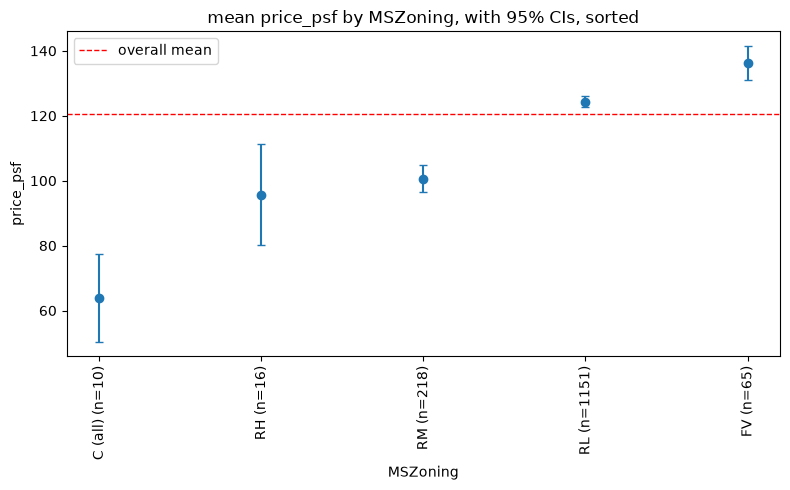

,n,mean,std,se,ci_half
g,,,,,
C (all),10,63.952,18.896,5.975,13.518
RH,16,95.735,29.420,7.355,15.677
RM,218,100.667,30.955,2.097,4.132
RL,1151,124.293,29.860,0.880,1.727
FV,65,136.280,20.891,2.591,5.177


In [55]:
ui_controls = ['OverallQual', 'OverallCond', 'YearBuilt', 'GrLivArea']  # F-test repeated holding these fixed; [] for the raw test only

plot_group_means(df_data, col='price_psf', by='MSZoning', log=False, l_controls=ui_controls)

## Naive model

Start with a forward selection methodology to pick a number of numeric regressors that covers most of the variability. 

I've decided to start with 6 regressors - arbitrarily. 

Note that we're using 100% of the dataset here - this is not ML yet. 

In [56]:
# correlation of each numeric feature with the target, top n by absolute value
ui_target = 'SalePrice' # any numeric column of df_data

df_corr = (
    df_data.select_dtypes('number')
    .drop(columns=['Id', 'MSSubClass'])  # MSSubClass is a dwelling-type code, not a quantity
    .corr()[ui_target]
    .drop(ui_target)
    .to_frame('corr')
)
df_corr['abs_corr'] = df_corr['corr'].abs()
df_corr.sort_values('abs_corr', ascending=False).head(15)

,corr,abs_corr
OverallQual,0.790982,0.790982
GrLivArea,0.708624,0.708624
GarageCars,0.640409,0.640409
GarageArea,0.623431,0.623431
TotalBsmtSF,0.613581,0.613581
1stFlrSF,0.605852,0.605852
price_psf,0.575505,0.575505
FullBath,0.560664,0.560664
TotRmsAbvGrd,0.533723,0.533723
YearBuilt,0.522897,0.522897


In [57]:
# forward selection: pick regressors one at a time by partial correlation with log SalePrice, given those already chosen
# collinearity filter: skip candidates whose VIF against the chosen set is above ui_max_vif
ui_n_features = 6 # total number of features to select
ui_max_vif = 5
l_exclude = ['Id', 'SalePrice', 'price_psf', 'MSSubClass'] # never candidates (price_psf is built from the target; MSSubClass is a code, not a quantity)

l_chosen = []
l_candidates = [c for c in df_data.select_dtypes('number').columns if c not in l_exclude]
df_fs = df_data[l_candidates].assign(log_SalePrice=np.log(df_data['SalePrice'])).dropna() # complete rows only (drops 339, mostly LotFrontage NaNs)

def residualise(sl, l_regs):
    """Residuals of sl after an OLS on l_regs (plus a constant); with no regressors, just demeaned."""
    if not l_regs:
        return sl - sl.mean()
    X = sm.add_constant(df_fs[l_regs])
    return sm.OLS(sl, X).fit().resid

while len(l_chosen) < ui_n_features:
    e_y = residualise(df_fs['log_SalePrice'], l_chosen)
    df_round = pd.DataFrame(index=l_candidates, columns=['pcorr', 'vif'], dtype=float)
    for c in l_candidates:
        x_res = residualise(df_fs[c], l_chosen)
        df_round.loc[c, 'pcorr'] = x_res.corr(e_y)
        df_round.loc[c, 'vif'] = df_fs[c].var() / x_res.var() # = 1 / (1 - R^2 of c on the chosen set)

    best = df_round[df_round['vif'] <= ui_max_vif]['pcorr'].abs().idxmax()
    l_skipped = df_round.index[df_round['pcorr'].abs() > abs(df_round.loc[best, 'pcorr'])].tolist() # ranked higher but too collinear
    print(f"add {best}: partial corr {df_round.loc[best, 'pcorr']:.3f}, VIF {df_round.loc[best, 'vif']:.2f}, skipped for collinearity: {l_skipped}")
    l_chosen.append(best)
    l_candidates.remove(best)

add OverallQual: partial corr 0.828, VIF 1.00, skipped for collinearity: []
add GrLivArea: partial corr 0.433, VIF 1.58, skipped for collinearity: []
add YearBuilt: partial corr 0.385, VIF 1.62, skipped for collinearity: []
add OverallCond: partial corr 0.313, VIF 1.26, skipped for collinearity: []
add GarageCars: partial corr 0.267, VIF 1.85, skipped for collinearity: []
add BsmtFullBath: partial corr 0.261, VIF 1.04, skipped for collinearity: []


In [58]:
# OLS: log SalePrice on the forward-selected features
df_ols = df_data[l_chosen].assign(log_SalePrice=np.log(df_data['SalePrice'])).dropna() # complete rows for the chosen features only
X = sm.add_constant(df_ols[l_chosen])
y = df_ols['log_SalePrice']

model_naive = sm.OLS(y, X).fit(cov_type='HC1')  # robust standard errors with Heteroscedasticity-Consistent covariance matrix estimators
model_naive.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:          log_SalePrice   R-squared:                       0.836
Model:                            OLS   Adj. R-squared:                  0.835
Method:                 Least Squares   F-statistic:                     714.7
Date:                Tue, 27 Oct 2026   Prob (F-statistic):               0.00
Time:                        00:39:34   Log-Likelihood:                 588.54
No. Observations:                1460   AIC:                            -1163.
Df Residuals:                    1453   BIC:                            -1126.
Df Model:                           6                                         
Covariance Type:                  HC1                                         
================================================================================
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const            3.7063      0.479      7.732      0.000       2.767       4.646
OverallQual      0.0996      0.005     18.559      0.000       0.089       0.110
GrLivArea        0.0003   3.19e-05      8.854      0.000       0.000       0.000
YearBuilt        0.0034      0.000     14.446      0.000       0.003       0.004
OverallCond      0.0578      0.005     12.713      0.000       0.049       0.067
GarageCars       0.0930      0.012      7.715      0.000       0.069       0.117
BsmtFullBath     0.0941      0.011      8.481      0.000       0.072       0.116
==============================================================================
Omnibus:                      756.586   Durbin-Watson:                   1.988
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            18841.535
Skew:                          -1.881   Prob(JB):                         0.00
Kurtosis:                      20.192   Cond. No.                     2.35e+05
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC1)
[2] The condition number is large, 2.35e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

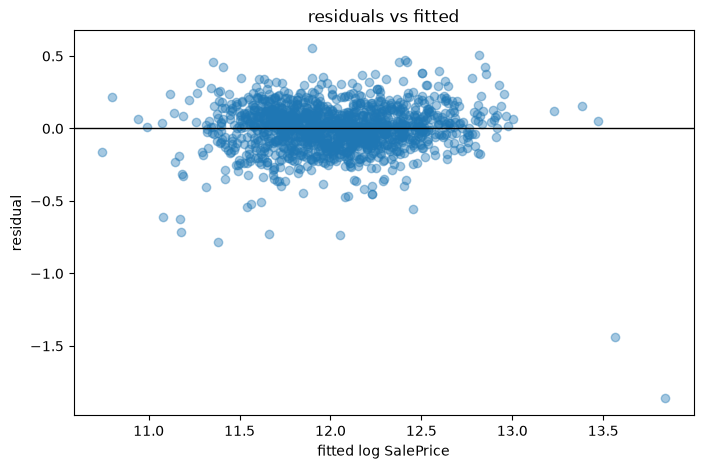

In [59]:
# residuals vs fitted values: a fan shape (spread growing with fitted price) = heteroskedasticity
ui_model = model_naive

## plotting charts below
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(ui_model.fittedvalues, ui_model.resid, alpha=0.4)
ax.axhline(0, color='black', linewidth=1)
ax.set_title('residuals vs fitted')
ax.set_xlabel('fitted log SalePrice')
ax.set_ylabel('residual')
plt.show()

## Naive+ model

Same idea as the naive model (forward selection → OLS), but predicting **price per sq ft** (predicted price = predicted psf × `GrLivArea`), on the cleaned, outlier-dropped, one-hot-encoded features, with **10** features, and validated by **5-fold CV**: each fold runs the *whole* procedure (preprocess → forward selection → OLS) on its 80% and is scored on its 20% with the Kaggle metric (RMSE on log price). Dummies held by fewer than 10 training houses aren't candidates (a 1-house dummy can fit that house exactly).

Final model, two ways: **(a)** average the 5 folds' coefficients (a feature a fold didn't pick counts as 0), **(b)** rerun the procedure on 100% of the training data.

Target choice (CV RMSE on log price): raw psf 0.161, log psf (`ui_log_psf = True`) 0.152, log price (first version of naive+) 0.154.

Is (a) better than (b)? Checked on 20 random 80/20 splits, with the log-price target (both built on the 80%, scored on the untouched 20%): (a) RMSE 0.160 vs (b) 0.163, (a) better in 17 of 20. Small but consistent. Why: forward selection is *unstable* (small data changes swap features in and out, see the fold table), and averaging models that made different picks smooths that out. That's the idea behind bagging (ensemble methods, week 7). For OLS on a *fixed* feature set, averaging fold fits wouldn't help, since each fit sees only 80% of the data.

The CV score's main job is honesty: it's an estimate of out-of-sample error for the whole procedure, selection included, which the naive model never had.

In [ ]:
# naive+ : forward selection + OLS predicting price per sq ft, on the cleaned, encoded features, validated with 5-fold CV
ui_n_features = 10
ui_max_vif = 5
ui_min_support = 10  # a dummy must be 1 for at least this many training houses to be a candidate (a 1-house dummy can fit that house exactly)
ui_n_folds = 5

ui_log_psf = False  # False: target = price per sq ft; True: target = log(price per sq ft)

sl_psf_train = df_train['SalePrice'] / df_train['GrLivArea']
sl_y_train = np.log(sl_psf_train) if ui_log_psf else sl_psf_train

def to_price(y_hat, df_X):
    """Model output (psf or log psf) -> sale price, using each house's GrLivArea."""
    psf_hat = np.exp(y_hat) if ui_log_psf else np.clip(y_hat, 1, None)  # clip: guard against a (very unlikely) negative psf
    return psf_hat * df_X['GrLivArea']

def rmse_log_price(price_hat, price_true):
    """The Kaggle metric: RMSE between log predicted and log true prices."""
    return np.sqrt(np.mean((np.log(price_hat) - np.log(price_true)) ** 2))

def residualise_all(M, Z):
    """Residuals of every column of M after OLS on Z (Z includes the constant)."""
    beta = np.linalg.lstsq(Z, M, rcond=None)[0]
    return M - Z @ beta

def forward_select(df_X, sl_y, n_features=ui_n_features, max_vif=ui_max_vif, min_support=ui_min_support):
    """Forward selection by partial correlation with sl_y, skipping candidates with VIF > max_vif against the chosen set."""
    l_cand = [c for c in df_X.columns if df_X[c].nunique() > 2 or df_X[c].sum() >= min_support]
    M, y = df_X[l_cand].to_numpy(float), sl_y.to_numpy(float)
    l_chosen = []
    while len(l_chosen) < n_features:
        Z = np.column_stack([np.ones(len(y))] + [df_X[c].to_numpy(float) for c in l_chosen])
        e_y = residualise_all(y[:, None], Z)[:, 0]
        M_res = residualise_all(M, Z)
        var_res = M_res.var(axis=0)
        with np.errstate(divide='ignore', invalid='ignore'):
            vif = M.var(axis=0) / var_res
            pcorr = (M_res * e_y[:, None]).mean(axis=0) / np.sqrt(var_res * e_y.var())
        pcorr[(vif > max_vif) | ~np.isfinite(pcorr) | np.isin(l_cand, l_chosen)] = 0
        l_chosen.append(l_cand[int(np.argmax(np.abs(pcorr)))])
    return l_chosen

## 5-fold CV: each fold runs the WHOLE procedure (preprocess -> forward selection -> OLS) on its 80%, scores on its 20%
kfold = KFold(n_splits=ui_n_folds, shuffle=True, random_state=0)
l_fold_rmse, l_fold_coefs = [], []
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='Found unknown categories')  # rare levels missing from a fold's 80%: encoded as baseline
    for k, (idx_tr, idx_va) in enumerate(kfold.split(df_X_train)):
        pre = clone(preprocess)
        df_tr = pre.fit_transform(df_X_train.iloc[idx_tr])
        df_va = pre.transform(df_X_train.iloc[idx_va])
        y_tr = sl_y_train.iloc[idx_tr]
        l_sel = forward_select(df_tr, y_tr)
        res = sm.OLS(y_tr, sm.add_constant(df_tr[l_sel])).fit()
        y_hat = res.predict(sm.add_constant(df_va[l_sel], has_constant='add'))
        l_fold_rmse.append(rmse_log_price(to_price(y_hat, df_X_train.iloc[idx_va]), df_train['SalePrice'].iloc[idx_va]))  # scored like Kaggle
        l_fold_coefs.append(res.params.rename(f'fold {k + 1}'))

print('validation RMSE on log price (the Kaggle metric) per fold:', np.round(l_fold_rmse, 4))
print(f'mean {np.mean(l_fold_rmse):.4f}, sd {np.std(l_fold_rmse):.4f}')

## which features each fold picked (coefficient where picked, blank where not)
df_fold_coefs = pd.concat(l_fold_coefs, axis=1)
df_fold_coefs.insert(0, 'n_folds', df_fold_coefs.drop(index='const').notna().sum(axis=1))
df_fold_coefs.sort_values('n_folds', ascending=False)

In [ ]:
# naive+ final model, two ways: (a) average the 5 folds' coefficients; (b) refit the whole procedure on 100% of the training data
## (a) averaged weights: a feature a fold didn't pick counts as 0 in that fold
df_coefs = df_fold_coefs.drop(columns='n_folds')
sl_coef_avg = df_coefs.fillna(0).mean(axis=1)

## (b) refit on 100%: preprocess -> forward selection -> OLS, all on df_X_train
with warnings.catch_warnings():
    warnings.filterwarnings('ignore', message='Found unknown categories')
    pre_full = clone(preprocess)
    df_X_train_enc = pre_full.fit_transform(df_X_train)
    df_X_test_enc = pre_full.transform(df_X_test)
l_chosen_plus = forward_select(df_X_train_enc, sl_y_train)
model_plus = sm.OLS(sl_y_train, sm.add_constant(df_X_train_enc[l_chosen_plus])).fit(cov_type='HC1')

## test-set predictions from both (psf -> price = psf x GrLivArea)
X_test_all = sm.add_constant(df_X_test_enc, has_constant='add')
sl_pred_avg = to_price(X_test_all[sl_coef_avg.index] @ sl_coef_avg, df_X_test)
sl_pred_refit = to_price(model_plus.predict(X_test_all[['const'] + l_chosen_plus]), df_X_test)
print(f'(a) uses {len(sl_coef_avg) - 1} features, (b) uses {len(l_chosen_plus)}; '
      f'the two test predictions differ by {np.mean(np.abs(np.log(sl_pred_avg / sl_pred_refit))):.1%} on average (in log terms)')
model_plus.summary()

## Predict + export

### Kaggle scores (benchmarks)

Public leaderboard score = RMSE on log price (lower is better). Times are Barcelona local time (Kaggle reports UTC).

| Submitted | File | Model | 5-fold CV RMSE | Public score | Kaggle ref |
|---|---|---|---|---|---|
| 2026-10-25 01:54 | `sub01_ols-fs6_2026-10-25T0149.csv` | Naive: OLS on log price, 6 forward-selected numeric features, raw data | – | **0.15889** | 57609755 |
| 2026-10-27 00:50 | `sub02_olsplus-psf-fs10-avg_2026-10-27T0048.csv` | Naive+: OLS on price per sq ft, 10 forward-selected features from the cleaned, outlier-dropped, encoded data; 5-fold averaged weights | 0.161 | **0.15121** | 57681429 |

In [60]:
datetime.now().strftime("%Y-%m-%dT%H%M")

'2026-10-27T0039'

In [61]:
export = False
ui_sub_name = 'sub01_ols-fs6_' + datetime.now().strftime("%Y-%m-%dT%H%M") # file name in submissions/ (no .csv)

if export:
    # predict SalePrice for test.csv with model_naive and export the Kaggle submission CSV    
    df_test = pd.read_csv(ROOT / "data" / "test.csv", **read_kwargs)

    ## features for the test set: same columns as the fit; fill NaNs with the TRAINING medians
    df_test_X = df_test[l_chosen].fillna(df_data[l_chosen].median())
    X_test = sm.add_constant(df_test_X, has_constant='add')

    ## predict log price, then transform back to price
    df_sub = pd.DataFrame({
        'Id': df_test['Id'],
        'SalePrice': np.exp(model_naive.predict(X_test)),
    })

    ## sanity checks before writing
    assert len(df_sub) == 1459 and df_sub['SalePrice'].notna().all()
    print(df_test[l_chosen].isna().sum()[lambda s: s > 0]) # which test NaNs got filled
    print(df_sub['SalePrice'].describe().round(0))

    path_sub = ROOT / "submissions" / f"{ui_sub_name}.csv"
    df_sub.to_csv(path_sub, index=False)
    print("saved", path_sub)

In [ ]:
export_plus = False
ui_plus_version = 'avg'  # 'avg' = (a) averaged fold weights, 'refit' = (b) refit on 100%
ui_sub_name = f'sub02_olsplus-psf-fs10-{ui_plus_version}_' + datetime.now().strftime("%Y-%m-%dT%H%M")  # file name in submissions/ (no .csv)

if export_plus:
    # export the naive+ predictions for test.csv (computed in the naive+ section)
    df_sub = pd.DataFrame({
        'Id': df_test['Id'],
        'SalePrice': sl_pred_avg if ui_plus_version == 'avg' else sl_pred_refit,
    })

    ## sanity checks before writing
    assert len(df_sub) == 1459 and df_sub['SalePrice'].notna().all()
    print(df_sub['SalePrice'].describe().round(0))

    path_sub = ROOT / "submissions" / f"{ui_sub_name}.csv"
    df_sub.to_csv(path_sub, index=False)
    print("saved", path_sub)

Another approach: let's try to predict price per square feet using the features, then use that to calculate our final predictions. 

Let's just compare a few features for a start. Just eyeballing, I'm gonna do an OLS with the following features, and with my intuition noted too: 
* `BldgType` - type of dwelling. This immediately stratifies the buyer base who may have very different economic conditions. 
* `YearBuilt` and `YearRemodAdd` - probably take the later of. Age of residence should have an impact on price (newer = better probably) but may require scaling; don't expect this to be a linear relationship. 
* `TotalBsmtSF` - maybe just start with a binary yes/no - I suspect houses with basements are different from houses without basements. 
* `CentralAir` - central air conditioning. Just because it's binary and it's easy ^_^
* `1stFlrSF`, `2ndFlrSF` - maybe enginner a total square footage? 
* `Bedroom`, `Kitchen`
* `GarageArea`
* `PoolArea`